<IPython.core.display.Javascript object>

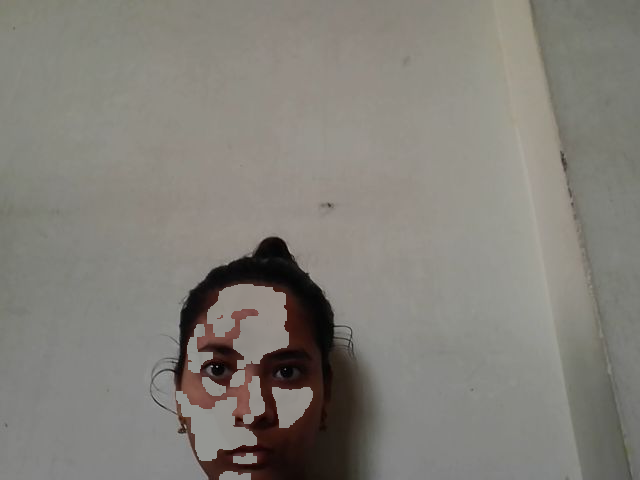

Stream Finished.


In [9]:
import time
import cv2
import numpy as np
import base64
import io
from google.colab.patches import cv2_imshow
from google.colab.output import eval_js
from IPython.display import display, Javascript
import IPython

# --- Helper functions for Colab webcam capture ---
def video_stream():
  js = Javascript('''
    var video;
    var div = null;
    var stream;
    var captureCanvas;
    var imgElement;
    var labelVal = '';

    function removeDom() {
       stream.getVideoTracks()[0].stop();
       video.remove();
       div.remove();
       video = null;
       div = null;
       imgElement = null;
    }

    async function createDom() {
      if (div !== null) {
        return;
      }

      div = document.createElement('div');
      div.style.border = '2px solid black';
      div.style.padding = '10px';
      div.style.width = '640px';
      div.style.margin = '0 auto';

      const label = document.createElement('div');
      label.innerHTML = "<b>Webcam Live Stream</b>";
      div.appendChild(label);

      video = document.createElement('video');
      video.style.display = 'block';
      video.width = 640;
      video.height = 480;
      video.autoplay = true;
      div.appendChild(video);

      const shutdownBtn = document.createElement('button');
      shutdownBtn.textContent = 'Stop Stream';
      shutdownBtn.style.marginTop = '10px';
      shutdownBtn.onclick = () => { removeDom(); };
      div.appendChild(shutdownBtn);

      document.body.appendChild(div);

      stream = await navigator.mediaDevices.getUserMedia({video: true});
      video.srcObject = stream;
      await video.play();

      captureCanvas = document.createElement('canvas');
      captureCanvas.width = 640;
      captureCanvas.height = 480;
    }

    async function streamFrame() {
      await createDom();
      if (video === null) {
         return null;
      }
      var context = captureCanvas.getContext('2d');
      context.drawImage(video, 0, 0, 640, 480);
      return captureCanvas.toDataURL('image/jpeg', 0.8);
    }

    window.streamFrame = streamFrame;
    ''')
  display(js)

def js_to_image(js_reply):
  if js_reply is None:
    return None
  image_bytes = base64.b64decode(js_reply.split(',')[1])
  jpg_as_np = np.frombuffer(image_bytes, dtype=np.uint8)
  img = cv2.imdecode(jpg_as_np, flags=cv2.IMREAD_COLOR)
  return img

# 1. Start Web Camera stream helper
video_stream()

# 2. Capture the background
print("Move out of the frame. Capturing background in 3 seconds...")
time.sleep(3)

background_frames = []
print("Capturing background frames...")
for _ in range(30):
    js_reply = eval_js('streamFrame()')
    if not js_reply:
        print("Error: Failed to capture frame.")
        break
    frame = js_to_image(js_reply)
    # Flip frame horizontally to mimic a mirror
    frame = cv2.flip(frame, 1)
    background_frames.append(frame)

# Compute average background to eliminate noise
background = np.mean(background_frames, axis=0).astype(np.uint8)
print("Background captured! Put on your red cloak.")

# Morphological operation kernels
kernel = np.ones((3, 3), np.uint8)

# 3. Stream and process the live video
# To prevent an infinite loop, we will capture 100 frames for display
for i in range(100):
    js_reply = eval_js('streamFrame()')
    if not js_reply:
        break

    img = js_to_image(js_reply)
    img = cv2.flip(img, 1)

    # Convert color space from BGR to HSV
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

    # Detect red (split into two ranges)
    lower_red1 = np.array([0, 120, 70], dtype=np.uint8)
    upper_red1 = np.array([10, 255, 255], dtype=np.uint8)
    lower_red2 = np.array([170, 120, 70], dtype=np.uint8)
    upper_red2 = np.array([180, 255, 255], dtype=np.uint8)

    mask1 = cv2.inRange(hsv, lower_red1, upper_red1)
    mask2 = cv2.inRange(hsv, lower_red2, upper_red2)
    mask = cv2.bitwise_or(mask1, mask2)

    # Refine mask
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel, iterations=2)
    mask = cv2.morphologyEx(mask, cv2.MORPH_DILATE, kernel, iterations=1)

    # Invert mask to detect non-red regions
    mask_inv = cv2.bitwise_not(mask)

    # Generate outputs
    cloak_area = cv2.bitwise_and(background, background, mask=mask)
    live_area = cv2.bitwise_and(img, img, mask=mask_inv)
    final_output = cv2.add(cloak_area, live_area)

    # Clear previous cell output to simulate dynamic update
    IPython.display.clear_output(wait=True)

    # Re-inject the video helper so we don't lose the Javascript references
    video_stream()
    cv2_imshow(final_output)

print("Stream Finished.")